# 07 — 3GPP TR 37.885 urban V2X

**Purpose.** Generate the Annex-A urban grid and lane-constrained traffic, inspect
LOS/NLOSv/NLOS link state, sample snapshot channels, apply them to OFDM, and persist
a complete realization. Support is urban V2V only, and packaged tables remain
`pending_independent_review`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Generate a reproducible Option A scene

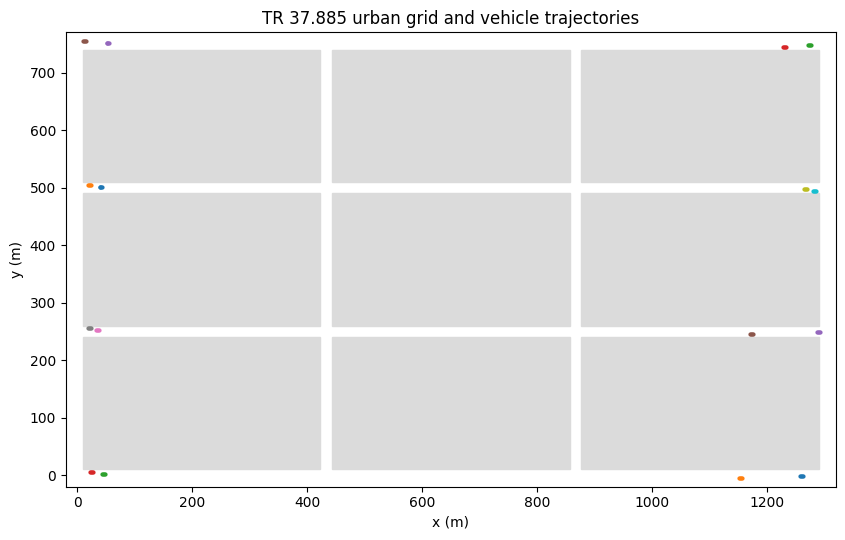

scene shape: (1, 16, 4) active vehicles at t=0: 16


In [2]:
from channel_dataset.channels.wireless import (
    TR37885TrafficConfig,
    TR37885UrbanGridSimulator,
    V2XSceneSamplingRequest,
)

simulator = TR37885UrbanGridSimulator(
    traffic=TR37885TrafficConfig(option="A", num_vehicles=16)
)


def make_scene():
    return simulator.generate(
        V2XSceneSamplingRequest(1, 4, execution, execution.random_stream(7701), "v2x-scene")
    )


scene = make_scene()
replayed_scene = make_scene()
assert torch.equal(scene.positions_m, replayed_scene.positions_m)
assert scene.shape == (1, 16, 4)

grid = simulator.grid
fig, ax = plt.subplots(figsize=(10, 5.5))
for block in grid.building_blocks:
    ax.add_patch(
        plt.Rectangle(
            (block.minimum_x_m, block.minimum_y_m),
            block.maximum_x_m - block.minimum_x_m,
            block.maximum_y_m - block.minimum_y_m,
            color="0.86",
        )
    )
positions = as_numpy(scene.positions_m[0])
for vehicle in range(scene.shape[1]):
    ax.plot(positions[vehicle, :, 0], positions[vehicle, :, 1], marker="o", markersize=2)
ax.set(xlim=(-20, grid.config.width_m + 20), ylim=(-20, grid.config.height_m + 20), title="TR 37.885 urban grid and vehicle trajectories", xlabel="x (m)", ylabel="y (m)", aspect="equal")
fig.tight_layout()
plt.show()
print("scene shape:", scene.shape, "active vehicles at t=0:", int(torch.sum(scene.active_mask[0, :, 0])))

## 2. Realize one CDL snapshot and inspect link conditions

In [3]:
from channel_dataset.channels.wireless import (
    LOS,
    NLOS,
    NLOSV,
    ChannelSamplingRequest,
    TR37885UrbanCDLChannel,
    TR37885UrbanCDLConfig,
    V2XChannelSamplingRequest,
)

sampling = ChannelSamplingRequest(1, 8, 15_000.0, execution, execution.random_stream(7702), "v2x-channel")
channel = TR37885UrbanCDLChannel(TR37885UrbanCDLConfig())
request = V2XChannelSamplingRequest(sampling, scene, 0, (0, 1), (2, 3))
realization = channel.realize(request)
codes = realization.link_conditions.condition_codes
active_codes = codes[realization.topology.link_mask]

assert torch.isin(active_codes, torch.tensor([LOS, NLOSV, NLOS], dtype=active_codes.dtype)).all()
assert torch.isfinite(realization.cir.coefficients).all()
print("CIR:", realization.cir.shape)
print("condition codes [rx, tx]:")
print(as_numpy(codes[0]))
print("standard baseline:", realization.diagnostics.values["standard_baseline"])

CIR: (1, 2, 1, 2, 1, 24, 8)
condition codes [rx, tx]:
[[[1 1 1 1]
  [1 1 1 1]]

 [[1 1 1 1]
  [1 1 1 1]]]
standard baseline: True


## 3. Apply the snapshot to an OFDM resource grid

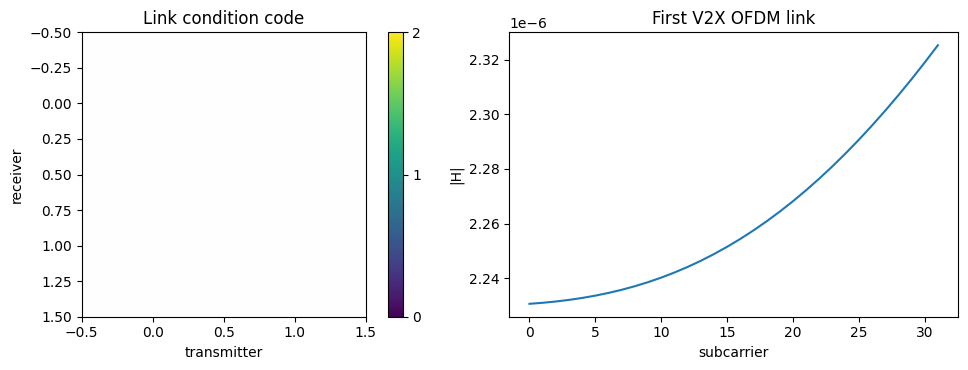

received grid: (1, 2, 1, 8, 32)


In [4]:
from channel_dataset.channels.wireless.operators import apply_ofdm
from channel_dataset.channels.wireless.transforms import cir_to_ofdm, subcarrier_frequencies

frequencies = subcarrier_frequencies(32, 15_000.0, execution)
response = cir_to_ofdm(realization.cir, frequencies)
signal = backend.ones((1, 2, 1, 8, 32), dtype=execution.complex_dtype)
received = apply_ofdm(response, signal)

assert tuple(received.shape) == (1, 2, 1, 8, 32)
assert torch.isfinite(received).all()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
image = axes[0].imshow(as_numpy(codes[0]), vmin=0, vmax=2, cmap="viridis")
axes[0].set(title="Link condition code", xlabel="transmitter", ylabel="receiver")
fig.colorbar(image, ax=axes[0], ticks=[LOS, NLOSV, NLOS])
axes[1].plot(as_numpy(torch.abs(response.coefficients[0, 0, 0, 0, 0, 0])))
axes[1].set(title="First V2X OFDM link", xlabel="subcarrier", ylabel="|H|")
fig.tight_layout()
plt.show()
print("received grid:", tuple(received.shape))

## 4. Carry immutable channel state across mobility snapshots

In [5]:
sequence_sampling = ChannelSamplingRequest(1, 4, 15_000.0, execution, execution.random_stream(7703), "v2x-sequence")
sequence = simulator.realize_sequence(channel, sequence_sampling, scene, (0,), (2,))
assert len(sequence) == scene.shape[2]
assert [item.state.snapshot_index for item in sequence] == list(range(scene.shape[2]))
print("snapshot indices:", [item.state.snapshot_index for item in sequence])
print("episode indices:", [int(item.state.episode_indices[0, 0, 0]) for item in sequence])

snapshot indices: [0, 1, 2, 3]
episode indices: [1, 1, 1, 1]


## 5. Controlled variation metadata and persistence

In [6]:
from tempfile import TemporaryDirectory

from channel_dataset.channels.wireless import load_v2x_realization, save_v2x_realization
from channel_dataset.config import load_config

controlled = load_config(ROOT / "configs/wireless/tr37885/urban_controlled_variation.yaml")
print("standard run diagnostic:", realization.diagnostics.values["standard_baseline"])
print("controlled config metadata:", dict(controlled.metadata))

with TemporaryDirectory() as temporary_directory:
    path = save_v2x_realization(Path(temporary_directory) / "v2x", realization)
    loaded = load_v2x_realization(path, execution)
assert torch.equal(loaded.cir.coefficients, realization.cir.coefficients)
assert torch.equal(loaded.link_conditions.condition_codes, codes)
print("complete V2X persistence round-trip: exact")

standard run diagnostic: True
controlled config metadata: {'scene_mode': 'controlled_variation', 'standard_baseline': False}


complete V2X persistence round-trip: exact


## Manual check and next experiments

- Compare traffic Options A and B, including the stopped north–south Option B fleet.
- Inspect `same_street`, `building_obstructed`, and blocker vehicle metadata.
- Compare stochastic system-level fading with fixed urban CDL profiles.
- Change a standardized traffic/grid parameter and verify diagnostics label the run non-baseline.